In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## correlation

**Figure 1: Reward model score against human rating for 300 responses.** Human ratings are 1–7 Likert scores averaged over annotators; the line is a least-squares fit. The reward model's scores correlate strongly with human ratings (Pearson r = 0.80, n = 300).

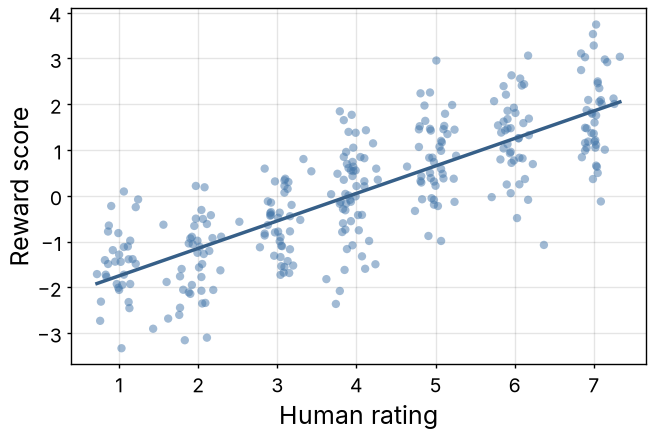

In [2]:
with open("../correlation.json") as f:
    data = json.load(f)
human = np.array(data["human_rating"])
reward = np.array(data["reward_score"])

fig, ax = plt.subplots(figsize=(3.25, 2))
ax.scatter(human, reward, s=9, color=colors["series-1"], edgecolors="none", alpha=0.5)
slope, intercept = np.polyfit(human, reward, 1)
fit_x = np.array([human.min(), human.max()])
ax.plot(fit_x, slope * fit_x + intercept, color=darken(colors["series-1"]))
ax.set_xlabel("Human rating")
ax.set_ylabel("Reward score")

fit_height(fig, ax, aspect=0.618)
fig.savefig("correlation.pdf")
fig.savefig("correlation.png")
plt.show()